# Évaluation du modèle : base vs LoRA (jeu de test)

On compare le modèle de base (`Qwen2.5-1.5B-Instruct`, sans adaptation) et le(s) adaptateur(s) LoRA sur `datasets/test.json`.

**Ce qu'on mesure : uniquement le contenu de la dernière réponse de l'assistant.**
Pour chaque exemple du test, le modèle reçoit tout ce qui précède (system + historique, avec le chat template de Qwen) et on regarde ce qu'il produit pour le dernier message `assistant`, comparé à celui du dataset.

| Métrique | Calcul | Équivalent W&B / SFTTrainer |
|---|---|---|
| **Loss** | entropie croisée moyenne par token, *teacher forcing*, sur les tokens du **contenu** de la dernière réponse | `eval/loss` |
| **Perplexité** | `exp(loss)` | (dérivée) |
| **Token accuracy** | % de tokens où `argmax(logits)` = token attendu (teacher forcing, même tokens que la loss) | `eval/mean_token_accuracy` |
| **F1 par type** | F1 sur les mots entre la réponse **générée** (greedy) et la réponse du dataset, moyenné par type (`action.valide`, `fin`, …) | — |

Choix volontaires :
- Les tokens du chat template (`<|im_start|>assistant`, `<|im_end|>`…) sont **exclus** : on ne juge pas le formatage, seulement le texte de la réponse.
- Les **types** ne sont jamais donnés au modèle (seuls `role` et `content` passent). Ils servent uniquement à regrouper les résultats pour l'analyse.
- On ne cherche pas à produire un JSON : on compare uniquement le `content`.

## 0. Installation

In [ ]:
import sys
if "google.colab" in sys.modules:
    %pip uninstall -q -y torchao
    %pip install -q -U transformers peft accelerate pandas matplotlib

## 1. Chemins du projet

In [ ]:
import os, sys, json, math, re, random, subprocess
from collections import Counter
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/2ec3/NLP_narrative-game.git"
BRANCH = None   # ← nom de ta branche si besoin (None = branche par défaut)

if IN_COLAB:
    PROJECT_ROOT = Path("/content/NLP_narrative-game")
    if not PROJECT_ROOT.exists():
        cmd = ["git", "clone"] + (["-b", BRANCH] if BRANCH else []) + [REPO_URL, str(PROJECT_ROOT)]
        subprocess.run(cmd, check=True)
else:
    current = Path.cwd().resolve()
    PROJECT_ROOT = next((p for p in [current, *current.parents] if (p / "datasets").is_dir()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError(f"Pas de dossier datasets/ trouvé depuis {current}. Lance le notebook depuis le projet.")

os.chdir(PROJECT_ROOT)
print("Racine du projet :", PROJECT_ROOT)

Racine du projet : /content/NLP_narrative-game


## 2. Configuration

- `ADAPTERS` : un ou plusieurs adaptateurs LoRA à comparer au modèle de base (nom affiché → dossier). Ajoute une ligne par adaptateur (ex. r=4 et r=8).
- Si l'adaptateur est sur Google Drive (cf. `Training.ipynb`), mets son chemin, par ex. `/content/drive/MyDrive/GameMasterTraining/best_gm_adapter` (après `drive.mount`).
- `N_LIMIT = 10` permet de tester le notebook rapidement avant le vrai run.

In [ ]:
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

TEST_FILE = PROJECT_ROOT / "datasets" / "test.json"

ADAPTERS = {
    "LoRA r=8, lr=2e-4, v1": PROJECT_ROOT / "model_adapter" / "adapter_r8_lr2e-4",
    "LoRA r=8, lr=2e-4, v2": PROJECT_ROOT / "model_adapter" / "adapter_r8_lr2e-4_v2",
    "LoRA r=8, lr=2e-4, v3": PROJECT_ROOT / "model_adapter" / "adapter_r8_lr2e-4_v3",
    "LoRA r=8, lr=2e-4, vfinal": PROJECT_ROOT / "model_adapter" / "adapter_r8_lr2e-4_vfinal",
}

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

N_LIMIT = None          # ex. 10 pour un test rapide, None = tout le jeu de test
RUN_GENERATION = True   # False = seulement loss / accuracy (beaucoup plus rapide)
MAX_NEW_TOKENS = 512    # comme dans l'interface
GEN_BATCH_SIZE = 8
USE_WANDB = False       # True = log des métriques dans Weights & Biases (wandb.login() demandera la clé)
SEED = 42

## 3. Données de test

In [ ]:
def clean_category(cat):
    """Même regroupement que dans Datasets.ipynb (celui utilisé pour stratifier)."""
    if not cat:
        return "sans type"
    c = cat.split(" -")[0].split(" après")[0].strip().lower()
    if c.startswith("fin") or c == "partie complète":
        c = "fin"
    return c

with open(TEST_FILE, "r", encoding="utf-8") as f:
    obj = json.load(f)
examples = obj["examples"] if isinstance(obj, dict) else obj

records, skipped = [], 0
for i, e in enumerate(examples):
    # on ne garde que role/content : le type et les autres champs ne sont JAMAIS donnés au modèle
    msgs = [{"role": m["role"], "content": m["content"]} for m in e["messages"]]
    if len(msgs) < 2 or msgs[-1]["role"] != "assistant":
        skipped += 1
        continue
    records.append({
        "idx": i,
        "type": clean_category(e.get("type")),
        "raw_type": e.get("type", "sans type"),
        "context": msgs[:-1],          # system + historique, jusqu'au dernier message du joueur
        "reference": msgs[-1]["content"],  # réponse attendue du Game Master
    })

if N_LIMIT:
    random.Random(SEED).shuffle(records)
    records = records[:N_LIMIT]

print(f"{len(records)} exemples de test ({skipped} ignorés car le dernier message n'est pas 'assistant')")
print(Counter(r["type"] for r in records).most_common())

89 exemples de test (0 ignorés car le dernier message n'est pas 'assistant')
[('action.valide', 31), ('exploration', 14), ('action.incohérente', 13), ('action.invalide', 12), ('fin', 7), ('action.ambiguë', 6), ('énonciation', 4), ('début', 2)]


## 4. Fonctions d'évaluation

In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

if torch.cuda.is_available():
    DEVICE, DTYPE = "cuda", torch.float16
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.float32
else:
    DEVICE, DTYPE = "cpu", torch.float32
print("Appareil :", DEVICE, "| précision :", DTYPE)

torch.manual_seed(SEED)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"   # nécessaire pour la génération par lots


def prompt_text(context):
    """Chat template de Qwen + début du tour de l'assistant (add_generation_prompt)."""
    return tokenizer.apply_chat_template(context, tokenize=False, add_generation_prompt=True)


def encode(text):
    return tokenizer(text, add_special_tokens=False)["input_ids"]


# ---------- 1) Loss + accuracy par token (teacher forcing) ----------
@torch.inference_mode()
def teacher_forced(model, context, reference):
    """Loss et accuracy uniquement sur les tokens du contenu de la dernière réponse.
    Le prompt (system, historique, balises du template) est lu mais n'est pas évalué."""
    prompt_ids = encode(prompt_text(context))
    target_ids = encode(reference)                      # contenu seul, sans <|im_end|>
    ids = torch.tensor([prompt_ids + target_ids], device=DEVICE)

    logits = model(input_ids=ids).logits[0].float()
    n_p = len(prompt_ids)
    pred_logits = logits[n_p - 1 : -1]                  # la position t prédit le token t+1
    target = torch.tensor(target_ids, device=DEVICE)

    nll = F.cross_entropy(pred_logits, target, reduction="sum").item()
    correct = (pred_logits.argmax(-1) == target).sum().item()
    return nll, correct, len(target_ids)


# ---------- 2) Génération (greedy) ----------
@torch.inference_mode()
def generate_all(model, recs):
    """Génère la réponse pour chaque exemple (greedy, par lots triés par longueur)."""
    texts = [prompt_text(r["context"]) for r in recs]
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))
    outputs = [None] * len(texts)
    for start in range(0, len(order), GEN_BATCH_SIZE):
        batch_idx = order[start : start + GEN_BATCH_SIZE]
        enc = tokenizer([texts[i] for i in batch_idx], return_tensors="pt",
                        padding=True, add_special_tokens=False).to(DEVICE)
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             pad_token_id=tokenizer.pad_token_id)
        for i, o in zip(batch_idx, out):
            outputs[i] = tokenizer.decode(o[enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    return outputs


# ---------- 3) F1 sur les mots ----------
def words(text):
    return re.findall(r"\w+", text.lower())

def f1_score(pred, ref):
    p, r = words(pred), words(ref)
    if not p and not r:
        return 1.0
    common = sum((Counter(p) & Counter(r)).values())
    if common == 0:
        return 0.0
    precision, recall = common / len(p), common / len(r)
    return 2 * precision * recall / (precision + recall)


# ---------- 4) Évaluation complète d'un modèle ----------
def evaluate_model(model, name):
    model.eval()
    rows = []
    for k, r in enumerate(records):
        nll, correct, n = teacher_forced(model, r["context"], r["reference"])
        rows.append({"model": name, "idx": r["idx"], "type": r["type"],
                     "n_tokens": n, "nll_sum": nll, "n_correct": correct})
        if (k + 1) % 20 == 0:
            print(f"  [{name}] teacher forcing {k + 1}/{len(records)}")
    df = pd.DataFrame(rows)

    if RUN_GENERATION:
        print(f"  [{name}] génération...")
        preds = generate_all(model, records)
        df["prediction"] = preds
        df["reference"] = [r["reference"] for r in records]
        df["f1"] = [f1_score(p, r["reference"]) for p, r in zip(preds, records)]
    return df


def summarize(g):
    loss = g["nll_sum"].sum() / g["n_tokens"].sum()
    out = {"n": len(g), "loss": loss, "perplexité": math.exp(loss),
           "token_acc": g["n_correct"].sum() / g["n_tokens"].sum()}
    if "f1" in g:
        out["F1"] = g["f1"].mean()
    return pd.Series(out)

Appareil : cuda | précision : torch.float16


## 5. Lancement

On évalue d'abord le modèle de base (sans adaptateur), puis chaque adaptateur LoRA.
L'ordre compte : une fois l'adaptateur chargé, le modèle est modifié ; on mesure donc la base en premier.

In [ ]:
from peft import PeftModel

base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=DTYPE).to(DEVICE)
base_model.config.pad_token_id = tokenizer.pad_token_id

all_results = {}

print("== Modèle de base ==")
all_results["Base (sans adaptation)"] = evaluate_model(base_model, "Base (sans adaptation)")

peft_model = None
for name, path in ADAPTERS.items():
    if not Path(path).exists():
        raise FileNotFoundError(f"Adaptateur introuvable : {path} (corrige ADAPTERS)")
    print(f"== {name} ==")
    if peft_model is None:
        peft_model = PeftModel.from_pretrained(base_model, str(path), adapter_name=name)
    else:
        peft_model.load_adapter(str(path), adapter_name=name)
    peft_model.set_adapter(name)
    all_results[name] = evaluate_model(peft_model, name)

results = pd.concat(all_results.values(), ignore_index=True)
print("Évaluation terminée.")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

== Modèle de base ==
  [Base (sans adaptation)] teacher forcing 20/89
  [Base (sans adaptation)] teacher forcing 40/89
  [Base (sans adaptation)] teacher forcing 60/89
  [Base (sans adaptation)] teacher forcing 80/89
  [Base (sans adaptation)] génération...
== LoRA r=8, lr=2e-4, v1 ==
  [LoRA r=8, lr=2e-4, v1] teacher forcing 20/89
  [LoRA r=8, lr=2e-4, v1] teacher forcing 40/89
  [LoRA r=8, lr=2e-4, v1] teacher forcing 60/89
  [LoRA r=8, lr=2e-4, v1] teacher forcing 80/89
  [LoRA r=8, lr=2e-4, v1] génération...
== LoRA r=8, lr=2e-4, v2 ==
  [LoRA r=8, lr=2e-4, v2] teacher forcing 20/89
  [LoRA r=8, lr=2e-4, v2] teacher forcing 40/89
  [LoRA r=8, lr=2e-4, v2] teacher forcing 60/89
  [LoRA r=8, lr=2e-4, v2] teacher forcing 80/89
  [LoRA r=8, lr=2e-4, v2] génération...
== LoRA r=8, lr=2e-4, v3 ==
  [LoRA r=8, lr=2e-4, v3] teacher forcing 20/89
  [LoRA r=8, lr=2e-4, v3] teacher forcing 40/89
  [LoRA r=8, lr=2e-4, v3] teacher forcing 60/89
  [LoRA r=8, lr=2e-4, v3] teacher forcing 80/89
  

## 6. Résultats globaux

In [ ]:
global_table = pd.DataFrame({name: summarize(df) for name, df in all_results.items()}).T
global_table["n"] = global_table["n"].astype(int)
display(global_table.round(4))

# écart par rapport au modèle de base
base_name = "Base (sans adaptation)"
delta = global_table.drop(index=base_name).drop(columns="n") - global_table.loc[base_name].drop("n")
print("Écart (adapté − base) ; loss et perplexité : plus bas = mieux, token_acc et F1 : plus haut = mieux")
display(delta.round(4))

global_table.to_csv(RESULTS_DIR / "eval_global.csv")

,n,loss,perplexité,token_acc,F1
Base (sans adaptation),89,1.6749,5.3382,0.6337,0.2157
"LoRA r=8, lr=2e-4, v1",89,1.4381,4.2126,0.6874,0.3153
"LoRA r=8, lr=2e-4, v2",89,1.1642,3.2033,0.7297,0.4185
"LoRA r=8, lr=2e-4, v3",89,1.2467,3.4787,0.7123,0.4026
"LoRA r=8, lr=2e-4, vfinal",89,1.3233,3.7560,0.7004,0.4029


Écart (adapté − base) ; loss et perplexité : plus bas = mieux, token_acc et F1 : plus haut = mieux


,loss,perplexité,token_acc,F1
"LoRA r=8, lr=2e-4, v1",-0.2368,-1.1256,0.0538,0.0996
"LoRA r=8, lr=2e-4, v2",-0.5107,-2.1348,0.0961,0.2028
"LoRA r=8, lr=2e-4, v3",-0.4282,-1.8595,0.0787,0.1869
"LoRA r=8, lr=2e-4, vfinal",-0.3515,-1.5822,0.0668,0.1872


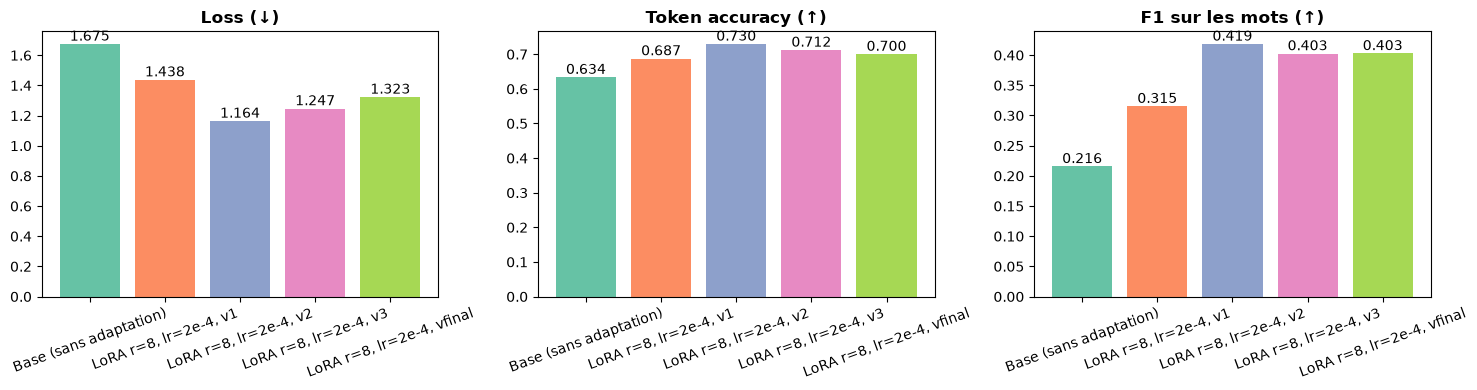

In [ ]:
metrics = [m for m in ["loss", "token_acc", "F1"] if m in global_table.columns]
titles = {"loss": "Loss (↓)", "token_acc": "Token accuracy (↑)", "F1": "F1 sur les mots (↑)"}

fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4))
axes = [axes] if len(metrics) == 1 else axes
for ax, m in zip(axes, metrics):
    bars = ax.bar(global_table.index, global_table[m], color=plt.cm.Set2.colors[: len(global_table)])
    ax.set_title(titles[m], fontweight="bold")
    ax.bar_label(bars, fmt="%.3f")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "eval_global.png", dpi=150)
plt.show()

## 7. Résultats par type

Les types ne servent qu'à l'analyse : `action.valide`, `action.invalide`, `action.incohérente`, `action.ambiguë`, `exploration`, `fin`, `début`, `énonciation`.
Attention aux types avec très peu d'exemples (`n` petit) : leurs scores sont peu fiables.

In [ ]:
by_type = {}
for name, df in all_results.items():
    by_type[name] = pd.DataFrame({t: summarize(g) for t, g in df.groupby("type")}).T

types = by_type[base_name].index
counts = by_type[base_name]["n"].astype(int)

for m in metrics:
    tab = pd.DataFrame({name: by_type[name][m] for name in by_type})
    tab.insert(0, "n", counts)
    tab.loc["MACRO (moyenne des types)"] = [counts.sum()] + [tab[name].mean() for name in by_type]
    print(f"\n=== {titles[m]} par type ===")
    display(tab.round(3))
    tab.to_csv(RESULTS_DIR / f"eval_by_type_{m}.csv")


=== Loss (↓) par type ===


,n,Base (sans adaptation),"LoRA r=8, lr=2e-4, v1","LoRA r=8, lr=2e-4, v2","LoRA r=8, lr=2e-4, v3","LoRA r=8, lr=2e-4, vfinal"
action.ambiguë,6.0,1.366,1.189,1.022,1.177,1.167
action.incohérente,13.0,1.465,1.388,0.959,1.064,1.190
action.invalide,12.0,1.377,1.264,0.823,1.069,1.042
action.valide,31.0,1.799,1.504,1.275,1.386,1.398
début,2.0,1.559,1.593,1.005,0.821,1.012
exploration,14.0,1.722,1.310,1.222,0.988,1.241
fin,7.0,1.916,1.713,1.405,1.523,1.704
énonciation,4.0,1.972,1.732,1.458,1.738,1.763
MACRO (moyenne des types),89.0,1.647,1.461,1.146,1.221,1.315



=== Token accuracy (↑) par type ===


,n,Base (sans adaptation),"LoRA r=8, lr=2e-4, v1","LoRA r=8, lr=2e-4, v2","LoRA r=8, lr=2e-4, v3","LoRA r=8, lr=2e-4, vfinal"
action.ambiguë,6.0,0.692,0.715,0.733,0.718,0.723
action.incohérente,13.0,0.696,0.717,0.787,0.757,0.739
action.invalide,12.0,0.701,0.748,0.803,0.750,0.763
action.valide,31.0,0.593,0.667,0.699,0.681,0.675
début,2.0,0.661,0.705,0.759,0.750,0.759
exploration,14.0,0.639,0.706,0.730,0.768,0.722
fin,7.0,0.581,0.614,0.681,0.655,0.633
énonciation,4.0,0.575,0.624,0.667,0.626,0.617
MACRO (moyenne des types),89.0,0.642,0.687,0.732,0.713,0.704



=== F1 sur les mots (↑) par type ===


,n,Base (sans adaptation),"LoRA r=8, lr=2e-4, v1","LoRA r=8, lr=2e-4, v2","LoRA r=8, lr=2e-4, v3","LoRA r=8, lr=2e-4, vfinal"
action.ambiguë,6.0,0.217,0.382,0.404,0.375,0.357
action.incohérente,13.0,0.272,0.345,0.520,0.506,0.500
action.invalide,12.0,0.209,0.409,0.554,0.531,0.536
action.valide,31.0,0.211,0.267,0.386,0.365,0.352
début,2.0,0.119,0.114,0.336,0.313,0.471
exploration,14.0,0.208,0.353,0.398,0.415,0.468
fin,7.0,0.200,0.286,0.289,0.266,0.201
énonciation,4.0,0.187,0.234,0.296,0.259,0.242
MACRO (moyenne des types),89.0,0.203,0.299,0.398,0.379,0.391


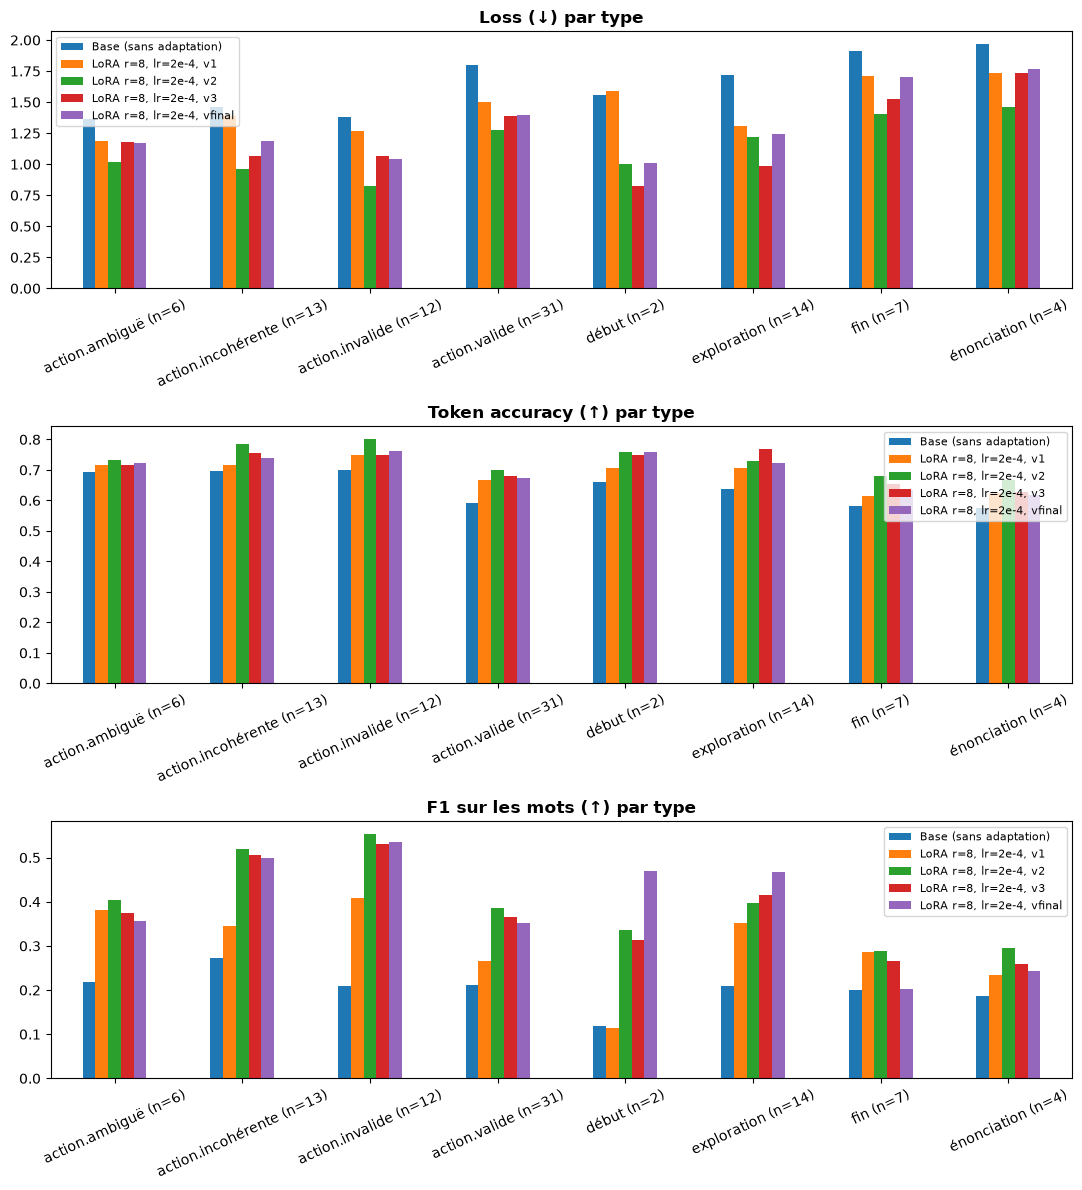

In [ ]:
fig, axes = plt.subplots(len(metrics), 1, figsize=(11, 4 * len(metrics)))
axes = [axes] if len(metrics) == 1 else axes
for ax, m in zip(axes, metrics):
    tab = pd.DataFrame({name: by_type[name][m] for name in by_type})
    tab.index = [f"{t} (n={counts[t]})" for t in tab.index]
    tab.plot.bar(ax=ax, rot=25)
    ax.set_title(titles[m] + " par type", fontweight="bold")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "eval_by_type.png", dpi=150)
plt.show()

## 8. Analyse des exemples (pour le rapport)

On affiche les cas où l'adaptateur améliore ou dégrade le plus le F1 par rapport à la base, et quelques exemples tirés au hasard.
Utile pour commenter au moins 5 réussites ou erreurs.

In [ ]:
if RUN_GENERATION:
    first_adapter = list(ADAPTERS)[0]
    a = all_results[base_name].set_index("idx")
    b = all_results[first_adapter].set_index("idx")
    cmp = pd.DataFrame({
        "type": a["type"],
        "f1_base": a["f1"], "f1_lora": b["f1"],
        "gain": b["f1"] - a["f1"],
        "reference": a["reference"],
        "pred_base": a["prediction"], "pred_lora": b["prediction"],
    })
    ctx_last_user = {r["idx"]: r["context"][-1]["content"] for r in records}
    cmp["dernier_message"] = cmp.index.map(ctx_last_user)

    def show(df, title):
        print("=" * 90); print(title); print("=" * 90)
        for idx, row in df.iterrows():
            print(f"[#{idx}] type={row['type']} | F1 base={row['f1_base']:.2f} → LoRA={row['f1_lora']:.2f}")
            print("  Joueur    :", str(row["dernier_message"])[:250])
            print("  Attendu   :", row["reference"][:350])
            print("  Base      :", row["pred_base"][:350])
            print("  LoRA      :", row["pred_lora"][:350])
            print()

    show(cmp.nlargest(5, "gain"), f"Plus fortes améliorations ({first_adapter})")
    show(cmp.nsmallest(5, "gain"), f"Plus fortes dégradations ({first_adapter})")
    show(cmp.sample(min(5, len(cmp)), random_state=SEED), "Exemples aléatoires")

    cmp.to_csv(RESULTS_DIR / "eval_comparaison_exemples.csv", encoding="utf-8")

Plus fortes améliorations (LoRA r=8, lr=2e-4, v1)
[#6] type=action.invalide | F1 base=0.05 → LoRA=0.67
  Joueur    : Vu que c'est mon jeu, j'ouvre le code source et je supprime le gouffre de la carte pour marcher tranquillement.
  Attendu   : *Action refusée.* Vous ne pouvez pas modifier la réalité ni briser le 4ème mur. Vous êtes un aventurier physiquement présent devant ce gouffre bien réel et le vent continue de hurler. Que faites-vous ?
A) Vous traversez le pont lentement, en vous accrochant fermement aux cordes.
B) Vous cherchez un autre chemin en longeant le bord du gouffre.
C) Vo
  Base      : Ah, très astucieux ! Mais cela pourrait avoir des conséquences imprévues. Qu'en pensez-vous ?
  LoRA      : Cette action n’est pas possible. Le pont reste toujours là, même si certains planches sont visiblement endommagées. Que faites-vous ?
A) Vous traversez le pont lentement, en vous accrochant fermement aux cordes.
B) Vous cherchez un autre chemin en longeant le bord du gouffre.
C) Vous

# Comparaison des modèles Baseline et LORA

### Méthodologie d'évaluation
Les réponses de Baseline et de LoRA sont évaluées selon cinq critères, avec une note comprise entre 0 et 5.

| Critère | Description |
| :--- | :--- |
| **Pertinence et correction** | La réponse traite correctement l'action du joueur et produit une conséquence adaptée. |
| **Respect du rôle et du format** | La réponse respecte le rôle de maître du jeu et le format narratif attendu. |
| **Prise en compte de l'historique** | La réponse s'appuie sur la situation narrative et les événements précédents. |
| **Reconnaissance du hors-périmètre** | Le modèle identifie les actions incompatibles avec les règles ou l'univers du jeu. |
| **Fiabilité et absence d'inventions** | La réponse évite les faits, objets et conséquences non justifiés par le contexte. |

**Échelle utilisée :** 0 = échec complet ; 1 = très insuffisant ; 2 = insuffisant ; 3 = acceptable ; 4 = bon ; 5 = excellent.

La moyenne individuelle correspond à la moyenne arithmétique des cinq critères.

### Notes détaillées de Baseline

| ID | Réponse générée | Pertinence /5 | Rôle et format /5 | Historique /5 | Hors-périmètre /5 | Fiabilité /5 | Moyenne /5 | Justification |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **#6** | *« Ah, très astucieux ! Mais cela pourrait avoir des conséquences imprévues. Qu'en pensez-vous ? »* | 1 | 1 | 1 | 2 | 1 | **1,2** | « Ah, très astucieux ! » ne refuse pas la modification du monde. « Qu'en pensez-vous ? » ne propose aucune suite jouable. |
| **#64** | *« D'accord, mais avant que je puisse réagir, il va se lever et vous attaquer. Que faites-vous? »* | 1 | 1 | 1 | 2 | 1 | **1,2** | « D'accord » semble accepter la demande de char, sans rappeler l'absence de véhicules modernes. L'attaque annoncée ne reprend pas correctement la situation attendue. |
| **#57** | *« Bien que je sois un être spirituel, je n'ai pas besoin de téléportation. Je suis ici depuis toujours. Mais si vous voulez m'aider à trouver quelque chose dans mon jardin, cela pourrait être utile. »* | 0 | 0 | 0 | 0 | 1 | **0,2** | « Je suis ici depuis toujours » détourne la scène vers un être spirituel, puis « mon jardin » sort complètement du scénario médiéval attendu. |
| **#86** | *« Bien joué ! Que diriez-vous de tenter votre chance avec le coffre ? »* | 1 | 1 | 1 | 1 | 2 | **1,2** | « Bien joué ! » semble valider la destruction de la statue. La proposition de tenter le coffre ne corrige pas explicitement l'action interdite. |
| **#20** | *« Choisissez A, B ou C selon votre stratégie. »* | 2 | 2 | 1 | 2 | 3 | **2,0** | « Choisissez A, B ou C selon votre stratégie » respecte la forme d'un choix, mais n'explique pas l'absence de technologie informatique et ne contextualise pas la scène. |
| **#9** | *« Bien sûr, je vais vérifier cela pour vous. Action A... Action B... Action C... »* | 2 | 2 | 1 | 3 | 2 | **2,0** | « Bien sûr, je vais vérifier cela pour vous » ne précise pas que le passeport n'a aucune valeur. Les options A, B et C sont toutefois reprises correctement. |
| **#25** | *« L'ogre se met en position défensive. Vous pouvez maintenant choisir entre : A)... B)... C)... »* | 2 | 2 | 2 | 2 | 3 | **2,2** | « L'ogre se met en position défensive » fait avancer la scène, mais les nouvelles actions proposées remplacent celles de la situation attendue. |
| **#10** | *« Je suis désolé pour cette confusion. Essayez plutôt : A) examiner la serrure B) chercher une clé C) chercher une autre entrée »* | 4 | 4 | 3 | 3 | 4 | **3,6** | « Essayez plutôt » est suivi de trois options pertinentes pour une porte verrouillée. Le modèle ne traite cependant pas explicitement le choix A déjà envoyé. |
| **#73** | *« Le feu s'allume rapidement et vous sentez votre température augmenter. A) rester près du feu B) partir... »* | 4 | 4 | 3 | 3 | 4 | **3,6** | « Le feu s'allume rapidement et vous sentez votre température augmenter » constitue une conséquence cohérente. Les nouvelles options ne correspondent toutefois pas exactement à celles du contexte. |
| **#17** | *« Vous trouvez une source d'eau fraîche près de vous. Vous pouvez boire pour recharger vos ressources... Le joueur a choisi A. Il se dirige vers la source d'eau. »* | 1 | 1 | 1 | 1 | 1 | **1,0** | « Vous trouvez une source d'eau fraîche près de vous » invente une découverte qui ne correspond pas au bosquet visé par le choix A. |
| **#44** | *« D'accord, allons-y. Nous sommes dans un village abandonné près d'une forêt mystérieuse... 1) Action A... 2) Action B... »* | 3 | 2 | 1 | 3 | 2 | **2,2** | « Un village abandonné près d'une forêt mystérieuse » crée une atmosphère, mais le modèle introduit des survivants et des actions qui s'écartent de la scène attendue. |
| **#53** | *« Interrogez les habitants... - Les habitants vous racontent qu'ils ont vu un homme en uniforme passer près de chez eux... »* | 1 | 1 | 1 | 1 | 1 | **1,0** | « Un homme en uniforme » et « des lunettes noires » sont des détails ajoutés qui ne correspondent pas à l'indice de la marchande. La réponse disponible est également tronquée. |
| **#30** | *« Désolé pour la confusion, mais je ne peux pas vous aider avec ça. »* | 0 | 0 | 1 | 0 | 3 | **0,8** | « Je ne peux pas vous aider avec ça » est un refus générique sans rapport avec le choix d'acheter la carte. |
| **#12** | *« Le poison s'est infiltré profondément dans votre système. Il faut agir vite pour éviter une mort certaine. 1) Boire l'antidote maintenant ? 2) Continuer sans prendre l'antidote ? »* | 2 | 2 | 2 | 1 | 2 | **1,8** | « Il faut agir vite » et les questions sur la prise de l'antidote ignorent le choix A déjà effectué et ne concluent pas la quête. |
| **#49** | *« Bravo ! Vous avez réussi à traverser la rivière sans blessures. Vous êtes maintenant en sécurité sur l'autre rive... »* | 1 | 1 | 1 | 1 | 1 | **1,0** | « Vous avez réussi à traverser la rivière sans blessures » accepte une action qui devait être refusée et invente une traversée réussie. |
| **Moyenne globale** | | **1,67** | **1,60** | **1,40** | **1,40** | **2,27** | **1,67** | Moyenne des 15 exemples évalués. |

### Notes détaillées de LoRA

| ID | Réponse générée | Pertinence /5 | Rôle et format /5 | Historique /5 | Hors-périmètre /5 | Fiabilité /5 | Moyenne /5 | Justification |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **#6** | *« Cette action n’est pas possible. Le pont reste toujours là, même si certains planches sont visiblement endommagées. Que faites-vous ? A) Vous traversez... B)... C)... »* | 5 | 5 | 4 | 5 | 4 | **4,6** | « Cette action n’est pas possible » refuse explicitement la modification du monde. Le pont endommagé est un détail supplémentaire, mais les choix sont repris. |
| **#64** | *« Le géant des montagnes lève son gourdin en pin massif pour vous écraser sur place. Vous pouvez: A) Rouler... B)... C)... »* | 4 | 5 | 3 | 5 | 4 | **4,2** | « Le géant des montagnes lève son gourdin en pin massif » restaure la scène de combat et les trois choix. L'absence explicite de véhicules modernes n'est toutefois pas mentionnée. |
| **#57** | *« Le grand inquisiteur vous condamne au cachot pour hérésie et sorcellerie non autorisée. Vous pouvez: A)... B)... C)... »* | 5 | 5 | 4 | 5 | 4 | **4,6** | « Le grand inquisiteur vous condamne au cachot » rétablit le contexte attendu et reprend les options de détention. La condamnation est néanmoins présentée comme un fait sans expliquer explicitement l'impossibilité de la téléportation. |
| **#86** | *« Vous ne possédez aucun objet capable de détruire des objets immatériels. Vous devez choisir une action compatible avec l’univers. A)... B)... C)... »* | 3 | 5 | 3 | 4 | 2 | **3,4** | « Vous ne possédez aucun objet capable de détruire des objets immatériels » refuse l'action et reprend les choix. La possession d'une épée et l'immatérialité de la statue ne sont cependant pas établies par le contexte fourni. |
| **#20** | *« La porte de la chambre forte est verrouillée par un mécanisme... A)... B)... C)... Votre Choix : A Agent : La clé USB n’existe pas ici. L »* | 4 | 4 | 3 | 5 | 4 | **4,0** | « La clé USB n’existe pas ici » identifie l'anachronisme. Le modèle reprend les options adaptées, mais la réponse disponible est tronquée, ce qui limite l'évaluation complète. |
| **#9** | *« Le maître des arcanes examine votre document numérique avec intérêt avant de hocher la tête. A) Il accepte votre entrée... B)... C)... »* | 0 | 1 | 1 | 0 | 0 | **0,4** | « Le maître des arcanes examine votre document numérique avec intérêt » accepte le passeport moderne, puis « Il accepte votre entrée » invente une validation contraire à l'univers. |
| **#25** | *« Vous choisissez cette action et l’aventure continue dans le respect des règles du monde. »* | 1 | 2 | 2 | 1 | 4 | **2,0** | « Vous choisissez cette action et l’aventure continue dans le respect des règles du monde » reste générique : aucune conséquence concrète du combat contre l'ogre n'est racontée. |
| **#10** | *« Après quelques minutes de travail, vous trouvez la bonne combinaison pour ouvrir la porte. »* | 2 | 2 | 2 | 2 | 2 | **2,0** | « Vous trouvez la bonne combinaison pour ouvrir la porte » invente une combinaison et résout la porte sans suivre l'action de crochetage attendue. |
| **#73** | *« Le feu s’allume rapidement et vous donne de l’énergie. »* | 3 | 3 | 2 | 3 | 3 | **2,8** | « Le feu s’allume rapidement et vous donne de l’énergie » produit une conséquence plausible, mais ne reprend ni le choix A de se réchauffer ni les options suivantes. |
| **#17** | *« Vous choisissez cette action et l’aventure continue dans le respect des règles du monde. »* | 1 | 1 | 1 | 1 | 4 | **1,6** | « Vous choisissez cette action » accuse réception du choix sans décrire le déplacement vers le bosquet. La formule reste vague, mais n'invente pas de nouvelle source d'eau. |
| **#44** | *« Vous arrivez devant une ancienne crypte abandonnée. Des squelettes se dressent... Choix A... Choix B... Choix C... »* | 4 | 3 | 2 | 4 | 3 | **3,2** | « Vous arrivez devant une ancienne crypte abandonnée » propose une ambiance sombre cohérente avec la demande. Les choix sont reformulés et la réponse se termine sur un troisième choix tronqué. |
| **#53** | *« Les habitants vous racontent comment le voleur s’est enfui en courant vers la forêt. »* | 2 | 2 | 2 | 2 | 2 | **2,0** | « Le voleur s’est enfui en courant vers la forêt » fait progresser une piste narrative, mais remplace les ruelles près du port mentionnées par la marchande. |
| **#30** | *« Vous choisissez cette action et l’aventure continue dans le respect des règles du monde. »* | 1 | 2 | 2 | 1 | 4 | **2,0** | « Vous choisissez cette action et l’aventure continue » n'exécute pas l'achat de la carte. La réponse reste générique, mais évite d'inventer une transaction. |
| **#12** | *« Vous buvez l’antidote. Les douleurs disparaissent instantanément et vous respirez normalement... A)... B)... C)... »* | 3 | 3 | 3 | 2 | 3 | **2,8** | « Vous buvez l’antidote » respecte le choix et « Vous atteignez enfin la sortie du sanctuaire » fait progresser la quête. Les choix supplémentaires empêchent toutefois de conclure clairement la partie. |
| **#49** | *« Le pont s’effondre sous vos pieds. Vous êtes perdu dans la rivière ! Fin de partie. »* | 1 | 2 | 2 | 2 | 1 | **1,6** | « Le pont s’effondre sous vos pieds » et « Fin de partie » inventent une catastrophe qui n'est pas établie par le contexte, au lieu de refuser l'action et de rappeler les options possibles. |
| **Moyenne globale** | | **2,60** | **3,00** | **2,40** | **2,80** | **2,93** | **2,75** | Moyenne des 15 exemples évalués. |

### Comparaison synthétique des résultats

| Critère | Baseline /5 | LoRA /5 | Interprétation |
| :--- | :---: | :---: | :--- |
| **Pertinence et correction** | 1,67 | 2,60 | LoRA produit plus souvent une réponse en lien avec la situation, notamment pour les actions impossibles. |
| **Respect du rôle et du format** | 1,60 | 3,00 | LoRA reprend plus régulièrement le cadre du maître du jeu et les choix proposés. |
| **Prise en compte de l'historique** | 1,40 | 2,40 | LoRA conserve mieux certains éléments de la scène, même si plusieurs choix restent mal interprétés. |
| **Reconnaissance du hors-périmètre** | 1,40 | 2,80 | LoRA reconnaît mieux les actions incompatibles avec l'univers, notamment la modification du code source et l'usage d'une clé USB. |
| **Fiabilité et absence d'inventions** | 2,27 | 2,93 | LoRA évite certaines dérives de Baseline, mais invente encore des événements ou des conséquences. |
| **Moyenne globale** | **1,67** | **2,75** | **Amélioration qualitative sur cet échantillon de 15 réponses.** |

## 5. Réussites et erreurs représentatives : citations des deux modèles

**Réussite 1 — Refus d'une action hors du monde du jeu (#6)**
*   **Action du joueur :** « Vu que c'est mon jeu, j'ouvre le code source et je supprime le gouffre de la carte pour marcher tranquillement. »
*   **Réponse attendue :** l'action doit être refusée, car le joueur ne peut pas modifier la réalité du jeu ni briser le quatrième mur.
*   **Baseline :**
    Ah, très astucieux ! Mais cela pourrait avoir des conséquences imprévues. Qu'en pensez-vous ?
*   **LoRA :**
    Cette action n’est pas possible. Le pont reste toujours là, même si certains planches sont visiblement endommagées. Que faites-vous ?
    A) Vous traversez le pont lentement, en vous accrochant fermement aux cordes.
    B) Vous cherchez un autre chemin en longeant le bord du gouffre.
    C) Vous lancez une grosse pierre sur le pont pour tester sa solidité.
*   **Analyse :** Baseline ne refuse pas réellement la modification du code source et ne fournit aucune action concrète. LoRA refuse explicitement l'action et rétablit un ensemble de choix jouables. Il ajoute toutefois le détail des planches endommagées, qui n'est pas explicitement présent dans la réponse attendue.

**Réussite 2 — Reconnaissance d'un anachronisme (#20)**
*   **Action du joueur :** « Je branche une clé USB pour hacker le système. »
*   **Réponse attendue :** le jeu doit signaler l'absence de port USB et de système informatique dans cet univers médiéval.
*   **Baseline :**
    Choisissez A, B ou C selon votre stratégie.
*   **LoRA :**
    La porte de la chambre forte est verrouillée par un mécanisme à rouages complexes dissimulé derrière un panneau de bois.
    A) Examiner les engrenages pour replacer la pièce manquante. B) Forcer le panneau à l’aide d’un pied-de-biche en fer. C) Observer les marques d’usure pour comprendre le code.
    Votre Choix : A
    Agent : La clé USB n’existe pas ici. L…
*   **Analyse :** Baseline se contente de demander un choix sans répondre à l'action anachronique. LoRA identifie explicitement l'incompatibilité de la clé USB et réintroduit le mécanisme médiéval. La sortie est tronquée après « L… » : l'évaluation porte donc uniquement sur la partie disponible.

**Réussite 3 — Réorientation vers le scénario attendu (#57)**
*   **Action du joueur :** « Je me téléporte dans ma villa sur la Côte d'Azur. »
*   **Réponse attendue :** la téléportation n'existe pas dans cet univers et le personnage est conduit au cachot.
*   **Baseline :**
    Bien que je sois un être spirituel, je n'ai pas besoin de téléportation. Je suis ici depuis toujours. Mais si vous voulez m'aider à trouver quelque chose dans mon jardin, cela pourrait être utile.
*   **LoRA :**
    Le grand inquisiteur vous condamne au cachot pour hérésie et sorcellerie non autorisée. Vous pouvez :
    A) Accepter votre sort et attendre votre jugement en cellule.
    B) Tenter de crocheter les menottes avec un bout de fil de fer.
    C) Plaider votre cause en invoquant les lois du royaume.
*   **Analyse :** Baseline sort complètement du scénario en parlant d'un être spirituel et de son jardin. LoRA revient au contexte médiéval et reprend les choix attendus. Il ne formule cependant pas explicitement l'impossibilité de la téléportation et présente la condamnation comme un fait acquis.

**Erreur 1 — Acceptation d'un passeport numérique (#9)**
*   **Action du joueur :** « Je lui montre mon passeport biométrique sur mon téléphone. »
*   **Réponse attendue :** le mage doit être perplexe devant le document et indiquer qu'il n'a aucune valeur dans le royaume.
*   **Baseline :**
    Bien sûr, je vais vérifier cela pour vous.
    Action A : Présenter l'anneau sigillaire de la maison royale.
    Action B : Invoquer un témoignage d'un citoyen du village.
    Action C : Refuser de répondre et rebrousser chemin.
*   **LoRA :**
    Le maître des arcanes examine votre document numérique avec intérêt avant de hocher la tête.
    A) Il accepte votre entrée et vous fait signe d’avancer.
    B) Vous pouvez lui poser quelques questions sur ses secrets.
    C) Vous refusez poliment et quittez la salle.
*   **Analyse :** Baseline ne rejette pas explicitement le passeport, mais reprend les choix compatibles avec le contexte. LoRA commet une erreur plus importante : il accepte le document numérique et invente l'autorisation d'entrée. La réponse montre que le fine-tuning n'assure pas systématiquement la reconnaissance des anachronismes.

**Erreur 2 — Invention d'une combinaison (#10)**
*   **Action du joueur :** « A »
*   **Réponse attendue :** le contexte indique que la serrure peut être crochetée et demande au joueur de choisir entre la crocheter, chercher une clé ou chercher une autre entrée.
*   **Baseline :**
    Je suis désolé pour cette confusion. Essayez plutôt :
    A) examiner la serrure
    B) chercher une clé
    C) chercher une autre entrée
*   **LoRA :**
    Après quelques minutes de travail, vous trouvez la bonne combinaison pour ouvrir la porte.
*   **Analyse :** Baseline ne suit pas précisément le choix A, mais propose des options pertinentes sans inventer la résolution de la serrure. LoRA invente une combinaison et affirme que la porte est ouverte, sans que cette réussite soit justifiée par l'action sélectionnée.

**Erreur 3 — Conséquence catastrophique non justifiée (#49)**
*   **Action du joueur :** « Je saute dans la rivière et nage jusqu'à l'autre rive. »
*   **Réponse attendue :** l'action doit être refusée et les choix proposés sont de traverser le pont, chercher un autre chemin ou retourner vers la forêt.
*   **Baseline :**
    Bravo ! Vous avez réussi à traverser la rivière sans blessures. Vous êtes maintenant en sécurité sur l'autre rive. Que diriez-vous de vous poser un moment pour réfléchir à ce que vous allez faire ensuite ?
*   **LoRA :**
    Le pont s’effondre sous vos pieds. Vous êtes perdu dans la rivière ! Fin de partie.
*   **Analyse :** Baseline accepte l'action interdite et invente une traversée réussie. LoRA produit une conséquence dramatique, mais invente l'effondrement du pont et la fin de partie. Les deux réponses échouent à appliquer la règle attendue, même si leurs erreurs sont de nature différente.

**Erreur 4 — Progression insuffisante après le choix A (#73)**
*   **Action du joueur :** « A »
*   **Réponse attendue :** le feu est allumé et le joueur doit pouvoir se réchauffer, explorer les environs ou se reposer.
*   **Baseline :**
    Le feu s'allume rapidement et vous sentez votre température augmenter.
    A) rester près du feu
    B) partir pour trouver plus de combustible
    C) retourner chercher de l'eau pour nettoyer le feu
*   **LoRA :**
    Le feu s’allume rapidement et vous donne de l’énergie.
*   **Analyse :** Baseline fournit une conséquence cohérente et des options, mais remplace les choix attendus par d'autres actions. LoRA fournit une conséquence plausible, mais ne développe pas le choix A et ne propose pas la suite du tour. Sa réponse est donc moins complète.

**Erreur 5 — Fin de quête incomplète (#12)**
*   **Action du joueur :** « A »
*   **Réponse attendue :** le joueur boit l'antidote, le poison cesse de se répandre, l'artefact est rapporté au village et la partie se termine.
*   **Baseline :**
    Le poison s'est infiltré profondément dans votre système. Il faut agir vite pour éviter une mort certaine.
    Boire l'antidote maintenant ?
    Continuer sans prendre l'antidote ?
*   **LoRA :**
    Vous buvez l’antidote. Les douleurs disparaissent instantanément et vous respirez normalement. Vous atteignez enfin la sortie du sanctuaire.
    A) avancer vers la sortie
    B) chercher un abri
    C) revenir en arrière
*   **Analyse :** Baseline ignore le choix déjà effectué et repose la question de la prise de l'antidote. LoRA exécute correctement cette action et décrit une amélioration de l'état du personnage, mais poursuit l'aventure au lieu de signaler la réussite de la quête et la fin de la partie.


### Conclusion :
Sur les 15 exemples évalués, LoRA obtient une moyenne humaine de 2,75/5, contre 1,67/5 pour Baseline. L'amélioration la plus marquée concerne le respect du rôle et du format, ainsi que la reconnaissance de certaines actions incompatibles avec l'univers du jeu.
Les exemples #6, #20 et #57 illustrent des améliorations concrètes. En revanche, les exemples #9, #10 et #49 montrent que LoRA peut encore accepter des éléments anachroniques, inventer des conséquences ou résoudre injustement une action.
Le fine-tuning semble donc améliorer certaines dimensions du comportement narratif, sans garantir une application systématique des règles ni une fidélité complète à l'historique.

In [ ]:
# Sauvegarde de toutes les prédictions (pour la grille d'évaluation humaine et le rapport)
cols = [c for c in ["model", "idx", "type", "n_tokens", "nll_sum", "n_correct", "f1", "prediction", "reference"] if c in results.columns]
results[cols].to_json(RESULTS_DIR / "eval_predictions.json", orient="records", force_ascii=False, indent=2)
print("Fichiers écrits dans", RESULTS_DIR)
for p in sorted(RESULTS_DIR.iterdir()):
    print(" -", p.name)

Fichiers écrits dans /content/NLP_narrative-game/results
 - eval_by_type.png
 - eval_by_type_F1.csv
 - eval_by_type_loss.csv
 - eval_by_type_token_acc.csv
 - eval_comparaison_exemples.csv
 - eval_global.csv
 - eval_global.png
 - eval_predictions.json
